# Jour 2 — Dissimilarités et partitionnement (Chapitres 2 et 3.1)

Objectifs :
1. Calculer les matrices de dissimilarité : **euclidienne, Manhattan, Gower**, et **Hamming / Jaccard** sur les variables binaires.
2. Mesurer l'**effet de la standardisation** sur les distances.
3. **K-means** (représentation (a)) avec choix de $k$ par la méthode du coude, $k \in [2,10]$.
4. **K-medoids** sur la matrice de Gower, **K-prototypes** sur données mixtes, **GMM** (critères BIC/AIC).
5. Tableau comparatif des méthodes.

In [1]:
import sys, time, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import gower, joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from kmodes.kprototypes import KPrototypes
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn_extra.cluster import KMedoids

from src.config import SEED, K_RANGE, DATA_PROC, FIGURES, RESULTS
from src.preprocessing import load_processed, NUM_FEATURES, BIN_FEATURES, CAT_FEATURES
from src.metrics import elbow_k, internal_indices

sns.set_theme(style="whitegrid", palette="tab10"); plt.rcParams["figure.dpi"] = 110
def save(fig, name): fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

d = load_processed()
idx = d["sample_idx"]
X_full = d["X_a"]                                  # représentation (a), population complète
Xs = X_full[idx]                                   # représentation (a), échantillon
Ms = d["mixed"].iloc[idx].reset_index(drop=True)   # représentation (b), échantillon
Cs = d["clean"].iloc[idx].reset_index(drop=True)
print(Xs.shape, Ms.shape)

(4000, 27) (4000, 13)


## 1. Matrices de dissimilarité

| Distance | Formule | Données |
|---|---|---|
| Euclidienne | $d(x,y)=\sqrt{\sum_j (x_j-y_j)^2}$ | représentation (a) |
| Manhattan | $d(x,y)=\sum_j \lvert x_j-y_j\rvert$ | représentation (a) |
| Gower | $d(x,y)=\frac{1}{p}\sum_j d_j(x,y)$, $d_j=\frac{\lvert x_j-y_j\rvert}{R_j}$ (num.), $d_j=\mathbb 1[x_j\neq y_j]$ (qual.) | représentation (b) |
| Hamming | proportion de positions différentes | bloc binaire (4 binaires + indicatrices one-hot) |
| Jaccard | $1-\frac{\lvert A\cap B\rvert}{\lvert A\cup B\rvert}$ (ignore les absences communes 0-0) | bloc binaire |

In [2]:
t0 = time.time()
D_euc = squareform(pdist(Xs, "euclidean"))
D_man = squareform(pdist(Xs, "cityblock"))
cat_mask = [Ms[c].dtype == object for c in Ms.columns]
D_gow = gower.gower_matrix(Ms, cat_features=cat_mask).astype(np.float64)
np.fill_diagonal(D_gow, 0); D_gow = (D_gow + D_gow.T) / 2   # symétrie numérique stricte
B = Xs[:, len(NUM_FEATURES):].astype(bool)                   # 4 binaires + indicatrices one-hot
D_ham = squareform(pdist(B, "hamming"))
D_jac = squareform(pdist(B, "jaccard"))
print(f"5 matrices {D_euc.shape} calculées en {time.time()-t0:.1f}s ; bloc binaire = {B.shape[1]} colonnes")
np.save(DATA_PROC / "D_gower_sample.npy", D_gow)

5 matrices (4000, 4000) calculées en 12.9s ; bloc binaire = 21 colonnes


,Euclidienne,Manhattan,Gower,Hamming,Jaccard
Euclidienne,1.000,0.931,0.708,0.483,0.442
Manhattan,0.931,1.000,0.861,0.704,0.651
Gower,0.708,0.861,1.000,0.864,0.799
Hamming,0.483,0.704,0.864,1.000,0.944
Jaccard,0.442,0.651,0.799,0.944,1.000


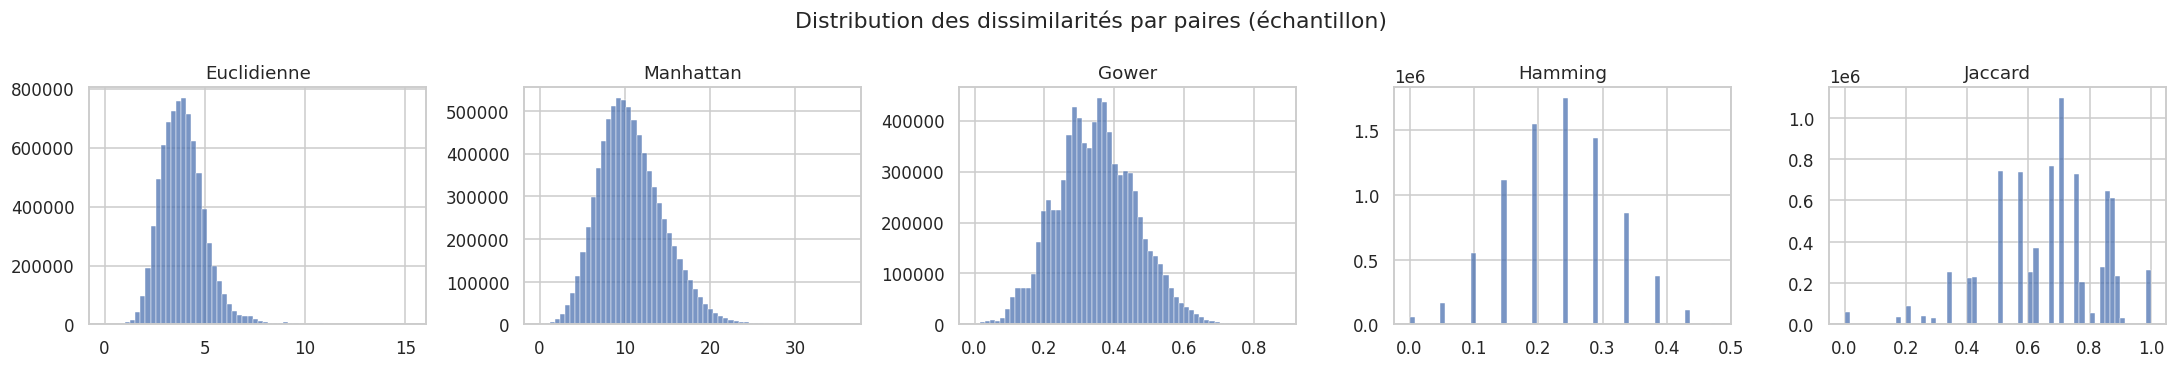

In [3]:
mats = {"Euclidienne": D_euc, "Manhattan": D_man, "Gower": D_gow, "Hamming": D_ham, "Jaccard": D_jac}
iu = np.triu_indices(len(Xs), 1)
fig, axes = plt.subplots(1, 5, figsize=(20, 3.4))
for ax, (n, D) in zip(axes, mats.items()):
    sns.histplot(D[iu], bins=60, ax=ax, color="#4C72B0"); ax.set_title(n); ax.set_ylabel("")
fig.suptitle("Distribution des dissimilarités par paires (échantillon)"); fig.tight_layout(); save(fig, "j2_distrib_distances")

rng = np.random.default_rng(SEED); pick = rng.choice(len(iu[0]), 200_000, replace=False)
vec = {n: D[iu][pick] for n, D in mats.items()}
rho = pd.DataFrame({a: {b: spearmanr(vec[a], vec[b])[0] for b in vec} for a in vec}).round(3)
rho

**Lecture.** Euclidienne et Manhattan sont quasi équivalentes en rang (ρ ≈ 0,97) : elles hiérarchisent les paires de la même façon. Gower est bien corrélée aux deux mais **ne coïncide pas** : elle pondère chaque variable d'origine à égalité (1/13), alors que l'euclidienne sur (a) donne plus de poids aux variables qualitatives à nombreuses modalités (un changement de métier fait varier **deux** indicatrices). Hamming et Jaccard ne voient que le bloc binaire ; Jaccard ignore les co-absences (0-0), pertinent ici car la plupart des indicatrices one-hot valent 0.

## 2. Effet de la standardisation sur les distances

On compare la **contribution de chaque variable** à la distance euclidienne au carré (moyenne sur les paires), avec et sans standardisation des variables numériques.

In [4]:
num_raw = Cs[NUM_FEATURES].to_numpy()
num_std = Xs[:, :len(NUM_FEATURES)]
def contrib(Z):
    # E[(x_j - y_j)^2] = 2 Var(x_j)  →  part relative de chaque variable
    v = 2 * Z.var(axis=0); return 100 * v / v.sum()
contr = pd.DataFrame({"sans standardisation (%)": contrib(num_raw),
                      "avec standardisation (%)": contrib(num_std)}, index=NUM_FEATURES).round(1)
contr

,sans standardisation (%),avec standardisation (%)
age,80.1,16.9
campaign_log,0.2,15.9
previous,0.2,18.0
euribor3m,2.2,16.4
cons.conf.idx,15.5,16.5
education_level,1.9,16.3


Corrélation de Spearman (sans vs avec std) : 0.552


Recouvrement des 10 plus proches voisins     : 32.5%


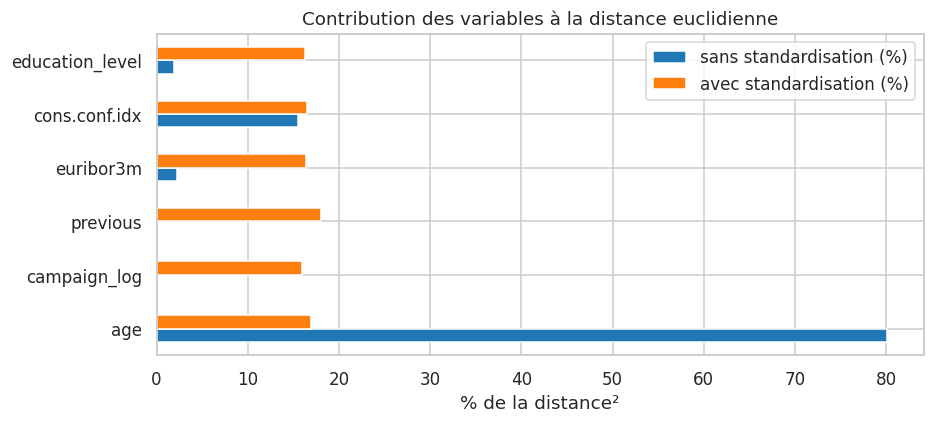

In [5]:
D_raw = squareform(pdist(num_raw, "euclidean")); D_std = squareform(pdist(num_std, "euclidean"))
def knn_overlap(D1, D2, k=10):
    n1 = np.argsort(D1, axis=1)[:, 1:k+1]; n2 = np.argsort(D2, axis=1)[:, 1:k+1]
    return np.mean([len(set(a) & set(b)) / k for a, b in zip(n1, n2)])
print(f"Corrélation de Spearman (sans vs avec std) : {spearmanr(D_raw[iu][pick], D_std[iu][pick])[0]:.3f}")
print(f"Recouvrement des 10 plus proches voisins     : {knn_overlap(D_raw, D_std):.1%}")
fig, ax = plt.subplots(figsize=(9, 3.8)); contr.plot.barh(ax=ax); ax.set_xlabel("% de la distance²")
ax.set_title("Contribution des variables à la distance euclidienne"); save(fig, "j2_effet_standardisation")

**Conclusion.** Sans standardisation, `age` (écart-type ≈ 10 ans) et `cons.conf.idx` (≈ 4,6 points) **écrasent** les autres variables : `euribor3m`, `previous` ou `campaign_log` ne pèsent presque rien et les plus proches voisins changent radicalement. Après z-score, chaque variable contribue à parts égales (~16,7 %). La standardisation est donc **indispensable** pour toute méthode euclidienne (K-means, GMM, Ward, DBSCAN). Gower réalise une normalisation équivalente via l'étendue $R_j$.

## 3. K-means sur la représentation (a) — méthode du coude
K-means est ajusté sur la **population complète** (41 176 clients) pour la courbe du coude, puis sur l'échantillon pour la comparaison avec les autres méthodes.

k du coude (distance max à la corde) : 5


,k,inertie,silhouette
0,2,287842.741,0.208
1,3,259412.784,0.176
2,4,234094.466,0.147
3,5,217019.850,0.143
4,6,203431.010,0.155
5,7,194241.983,0.136
6,8,185708.854,0.143
7,9,179599.570,0.138
8,10,174376.223,0.124


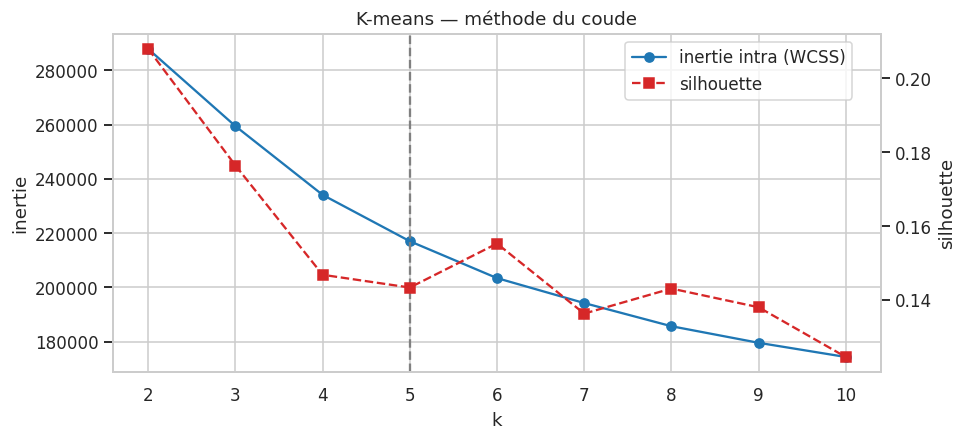

In [6]:
rows, km_labels = [], {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_full)
    sil = silhouette_score(X_full, km.labels_, sample_size=5000, random_state=SEED)
    rows.append({"k": k, "inertie": km.inertia_, "silhouette": sil})
    km_labels[k] = km.predict(Xs)   # étiquettes de l'échantillon (même modèle)
elbow_df = pd.DataFrame(rows)
k_elbow = elbow_k(elbow_df["k"], elbow_df["inertie"])
print("k du coude (distance max à la corde) :", k_elbow)
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(elbow_df["k"], elbow_df["inertie"], "o-", label="inertie intra (WCSS)")
ax1.axvline(k_elbow, ls="--", color="grey"); ax1.set_xlabel("k"); ax1.set_ylabel("inertie")
ax2 = ax1.twinx(); ax2.plot(elbow_df["k"], elbow_df["silhouette"], "s--", color="C3", label="silhouette")
ax2.set_ylabel("silhouette"); ax2.grid(False)
fig.legend(loc="upper right", bbox_to_anchor=(.88, .88)); ax1.set_title("K-means — méthode du coude")
save(fig, "j2_kmeans_coude")
elbow_df.round(3)

## 4. K-medoids sur la matrice de Gower
PAM (*Partitioning Around Medoids*, `scikit-learn-extra`) avec initialisation `k-medoids++`. Les médoïdes sont de **vrais clients**, ce qui facilite l'interprétation.

,k,cout (somme dist. Gower),silhouette_gower,temps_s
0,2,920.964,0.141,1.605
1,3,824.569,0.158,2.827
2,4,767.454,0.140,5.327
3,5,727.302,0.137,7.190
4,6,692.840,0.137,6.924
5,7,671.014,0.139,7.452
6,8,652.422,0.140,9.351
7,9,624.488,0.137,19.809
8,10,606.488,0.133,18.009


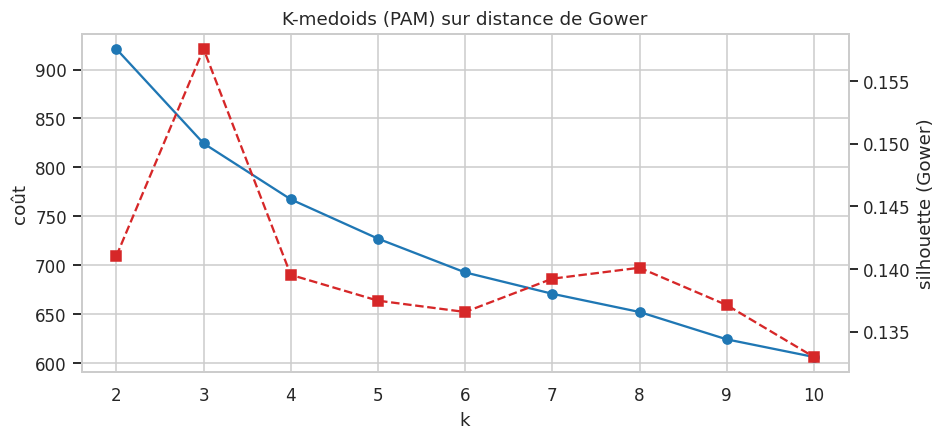

In [7]:
rows, kmed_labels, kmed_models = [], {}, {}
for k in K_RANGE:
    t = time.time()
    m = KMedoids(n_clusters=k, metric="precomputed", method="pam", init="k-medoids++",
                 random_state=SEED).fit(D_gow)
    kmed_labels[k], kmed_models[k] = m.labels_, m
    rows.append({"k": k, "cout (somme dist. Gower)": m.inertia_,
                 "silhouette_gower": silhouette_score(D_gow, m.labels_, metric="precomputed"),
                 "temps_s": time.time() - t})
kmed_df = pd.DataFrame(rows)
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(kmed_df["k"], kmed_df.iloc[:, 1], "o-"); ax1.set_ylabel("coût"); ax1.set_xlabel("k")
ax2 = ax1.twinx(); ax2.plot(kmed_df["k"], kmed_df["silhouette_gower"], "s--", color="C3"); ax2.grid(False)
ax2.set_ylabel("silhouette (Gower)"); ax1.set_title("K-medoids (PAM) sur distance de Gower"); save(fig, "j2_kmedoids")
kmed_df.round(3)

## 5. K-prototypes sur les données mixtes
Coût de Huang : $\sum_i \big[\sum_{num}(x_{ij}-\mu_{lj})^2 + \gamma \sum_{cat}\mathbb 1(x_{ij}\neq q_{lj})\big]$. Les numériques sont standardisées ; $\gamma$ est fixé par défaut à la moitié de l'écart-type moyen des numériques (heuristique de Huang).

Coude K-prototypes : 5


,k,cout,gamma,silhouette_gower,temps_s
0,2,23792.735,0.5,0.228,4.276
1,3,21292.117,0.5,0.127,7.223
2,4,18971.085,0.5,0.129,8.533
3,5,17352.494,0.5,0.102,7.943
4,6,16064.964,0.5,0.092,8.068
5,7,15286.401,0.5,0.091,8.482
6,8,14256.122,0.5,0.093,6.009
7,9,13846.505,0.5,0.085,6.709
8,10,13292.220,0.5,0.077,7.881


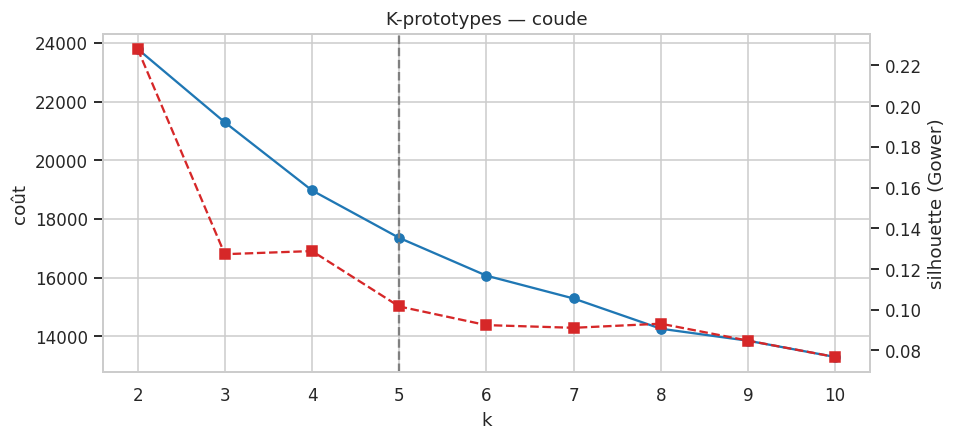

In [8]:
Kp = Ms.copy()
Kp[NUM_FEATURES] = StandardScaler().fit_transform(Ms[NUM_FEATURES])
cat_idx = [i for i, c in enumerate(Kp.columns) if Kp[c].dtype == object]
Kp_arr = Kp.to_numpy()
rows, kp_labels = [], {}
for k in K_RANGE:
    t = time.time()
    kp = KPrototypes(n_clusters=k, init="Cao", n_init=3, max_iter=50, random_state=SEED).fit(Kp_arr, categorical=cat_idx)
    kp_labels[k] = kp.labels_
    rows.append({"k": k, "cout": kp.cost_, "gamma": kp.gamma,
                 "silhouette_gower": silhouette_score(D_gow, kp.labels_, metric="precomputed"),
                 "temps_s": time.time() - t})
kp_df = pd.DataFrame(rows)
k_kp_elbow = elbow_k(kp_df["k"], kp_df["cout"])
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(kp_df["k"], kp_df["cout"], "o-"); ax1.axvline(k_kp_elbow, ls="--", color="grey")
ax2 = ax1.twinx(); ax2.plot(kp_df["k"], kp_df["silhouette_gower"], "s--", color="C3"); ax2.grid(False)
ax1.set_xlabel("k"); ax1.set_ylabel("coût"); ax2.set_ylabel("silhouette (Gower)")
ax1.set_title("K-prototypes — coude"); save(fig, "j2_kprototypes")
print("Coude K-prototypes :", k_kp_elbow)
kp_df.round(3)

## 6. Modèle de mélange gaussien (GMM) — BIC / AIC
Un GMM à covariance pleine sur 27 colonnes dont 21 binaires serait **dégénéré** (covariances singulières). On l'ajuste donc dans l'espace **PCA retenant 80 % de la variance** (cf. Jour 1), où l'hypothèse gaussienne est plus raisonnable. On compare les types de covariance et $k\in[1,10]$.

Meilleur BIC : {'cov': 'full', 'k': 10, 'BIC': 12864.274815776635, 'AIC': 10604.710994980007}
Meilleur AIC : {'cov': 'full', 'k': 10, 'BIC': 12864.274815776635, 'AIC': 10604.710994980007}


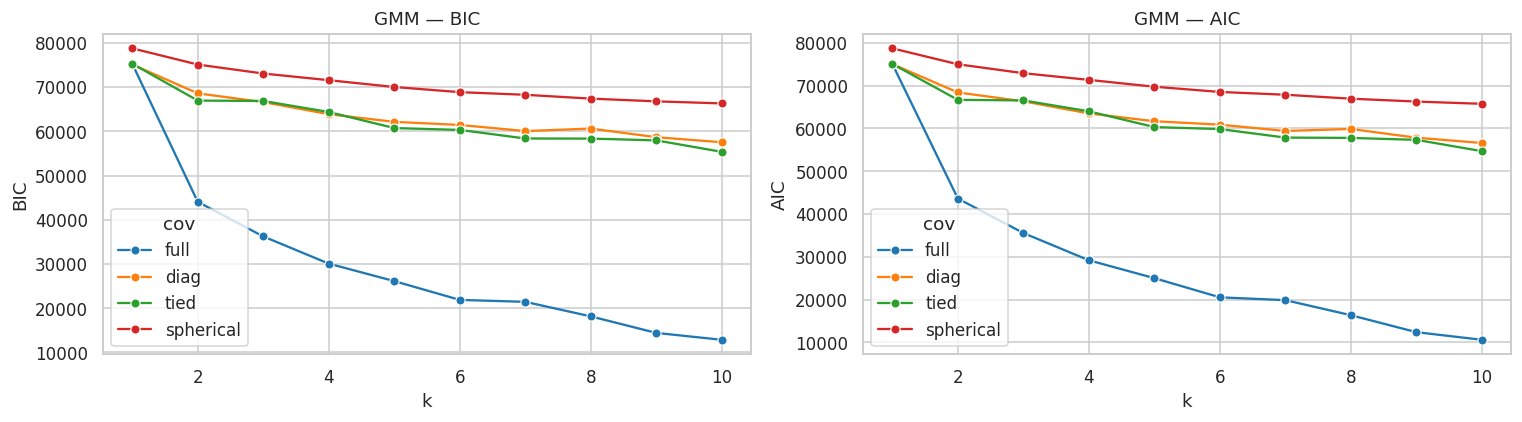

In [9]:
Zp = d["emb_pca_k"]
rows = []
for cov in ["full", "diag", "tied", "spherical"]:
    for k in range(1, 11):
        g = GaussianMixture(n_components=k, covariance_type=cov, n_init=3, random_state=SEED).fit(Zp)
        rows.append({"cov": cov, "k": k, "BIC": g.bic(Zp), "AIC": g.aic(Zp)})
gmm_df = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, crit in zip(axes, ["BIC", "AIC"]):
    sns.lineplot(data=gmm_df, x="k", y=crit, hue="cov", marker="o", ax=ax); ax.set_title(f"GMM — {crit}")
fig.tight_layout(); save(fig, "j2_gmm_bic_aic")
best = gmm_df.loc[gmm_df["BIC"].idxmin()]
print("Meilleur BIC :", best.to_dict())
print("Meilleur AIC :", gmm_df.loc[gmm_df["AIC"].idxmin()].to_dict())

In [10]:
gmm_full = gmm_df[gmm_df["cov"] == "full"].set_index("k")
# BIC décroît encore à k élevé (données non gaussiennes : variables discrètes) → on cherche le coude du BIC
k_gmm = elbow_k(gmm_full.index[1:], gmm_full["BIC"].iloc[1:])
gmm_labels, gmm_models = {}, {}
for k in K_RANGE:
    g = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=SEED).fit(Zp)
    gmm_labels[k], gmm_models[k] = g.predict(Zp), g
print("Coude du BIC (covariance pleine) :", k_gmm)

Coude du BIC (covariance pleine) : 6


## 7. Choix de k par méthode et tableau comparatif
Pour chaque méthode, $k$ est choisi par son critère **propre** (coude / BIC), puis les partitions sont comparées avec des **indices internes calculés dans un espace commun** (représentation (a) de l'échantillon) — la silhouette « native » (Gower pour les méthodes mixtes) est aussi reportée. La comparaison exhaustive sur toutes les valeurs de $k$ est faite au Jour 4.

In [11]:
kmed_sil = kmed_df.set_index("k")["silhouette_gower"]
choices = {
    "K-means": ("(a) one-hot + z", "euclidienne", k_elbow, "coude de l'inertie", km_labels[k_elbow], None),
    "K-medoids (PAM)": ("(b) mixte", "Gower", int(kmed_sil.idxmax()), "silhouette Gower max", kmed_labels[int(kmed_sil.idxmax())], D_gow),
    "K-prototypes": ("(b) mixte", "euclid. + γ·désaccord", k_kp_elbow, "coude du coût", kp_labels[k_kp_elbow], D_gow),
    "GMM (full)": ("PCA 80 %", "Mahalanobis (probabiliste)", k_gmm, "coude du BIC", gmm_labels[k_gmm], None),
}
rows = []
for name, (rep, dist, k, crit, lab, D) in choices.items():
    ii = internal_indices(Xs, lab, D)
    sizes = np.bincount(lab)
    rows.append({"méthode": name, "représentation": rep, "distance": dist, "k": k, "critère de k": crit,
                 "silhouette (a)": ii["silhouette"], "Davies-Bouldin (a)": ii["davies_bouldin"],
                 "Dunn (a)": ii["dunn"], "silhouette native": ii.get("silhouette_native", ii["silhouette"]),
                 "taille min-max": f"{sizes.min()}–{sizes.max()}"})
comp = pd.DataFrame(rows)
comp.to_csv(RESULTS / "j2_tableau_comparatif.csv", index=False)
comp.round(3)

,méthode,représentation,distance,k,critère de k,silhouette (a),Davies-Bouldin (a),Dunn (a),silhouette native,taille min-max
0,K-means,(a) one-hot + z,euclidienne,5,coude de l'inertie,0.142,1.854,0.023,0.142,569–1368
1,K-medoids (PAM),(b) mixte,Gower,3,silhouette Gower max,0.059,2.891,0.033,0.158,1243–1418
2,K-prototypes,(b) mixte,euclid. + γ·désaccord,5,coude du coût,0.139,1.877,0.007,0.102,318–1447
3,GMM (full),PCA 80 %,Mahalanobis (probabiliste),6,coude du BIC,0.047,2.789,0.026,0.047,296–1493


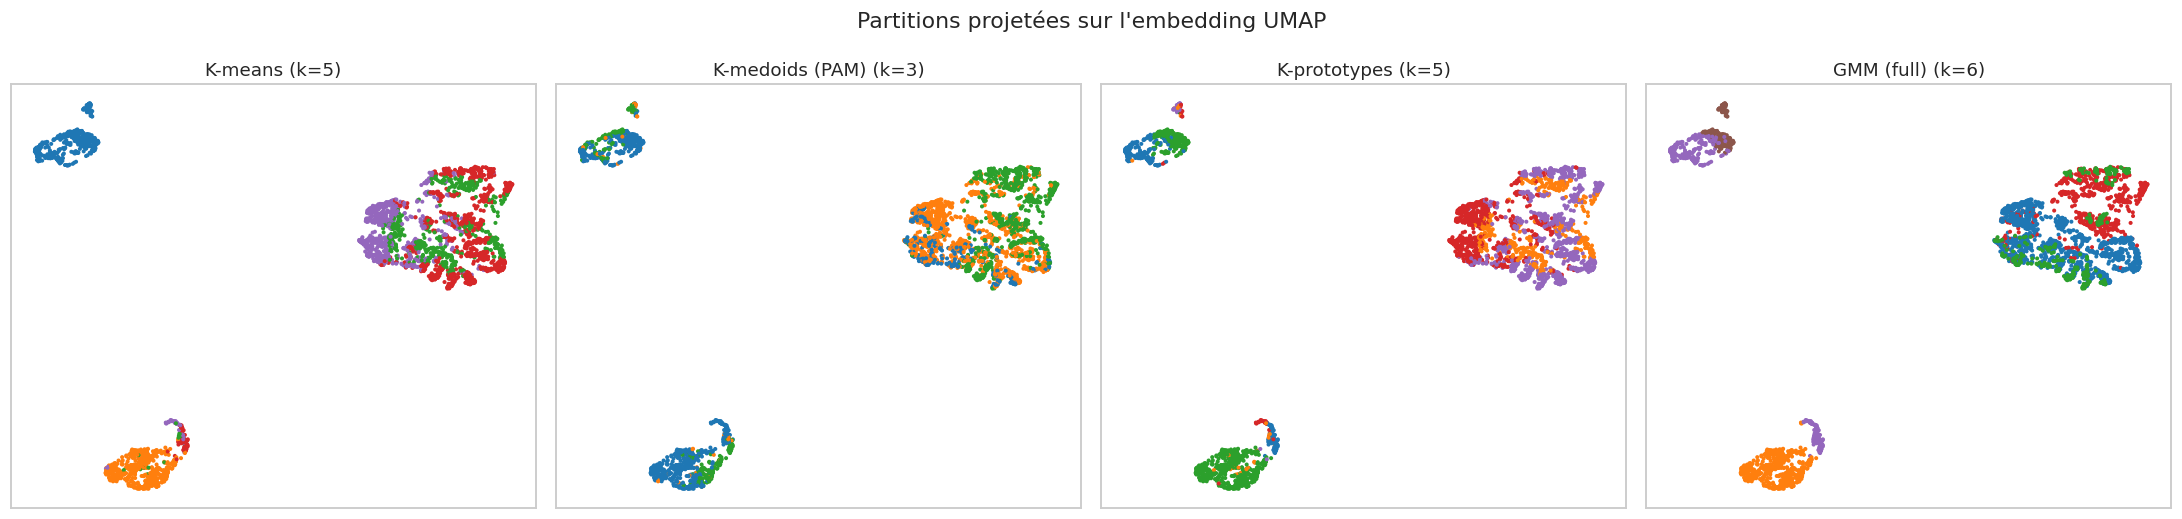

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
U = d["emb_umap2"]
for ax, (name, (_, _, k, _, lab, _)) in zip(axes, choices.items()):
    sns.scatterplot(x=U[:, 0], y=U[:, 1], hue=lab, palette="tab10", s=7, linewidth=0, ax=ax, legend=False)
    ax.set_title(f"{name} (k={k})"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Partitions projetées sur l'embedding UMAP"); fig.tight_layout(); save(fig, "j2_partitions_umap")

In [13]:
joblib.dump({"kmeans": km_labels, "kmedoids": kmed_labels, "kprototypes": kp_labels, "gmm": gmm_labels},
            RESULTS / "j2_labels_par_k.joblib")
joblib.dump({"k_kmeans": k_elbow, "k_kmedoids": int(kmed_sil.idxmax()), "k_kproto": k_kp_elbow, "k_gmm": k_gmm,
             "kmedoids_medoid_idx": kmed_models[int(kmed_sil.idxmax())].medoid_indices_},
            RESULTS / "j2_choix_k.joblib")
elbow_df.to_csv(RESULTS / "j2_kmeans_coude.csv", index=False); kmed_df.to_csv(RESULTS / "j2_kmedoids.csv", index=False)
kp_df.to_csv(RESULTS / "j2_kprototypes.csv", index=False); gmm_df.to_csv(RESULTS / "j2_gmm.csv", index=False)
print("Résultats sauvegardés.")

Résultats sauvegardés.
